<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5509-notebooks/main/_banners/opim5509_banner.svg" alt="OPIM 5509 banner" width="100%">

# FP2 · The Pinball Loss, Explained
### How a network learns a low, an expected and a high (optional, about 15 minutes)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5509-notebooks/blob/main/FinalProject/FP2_Pinball_Loss_Explained.ipynb)

Your FP2 LSTM gives **three numbers for each of the next 24 hours**: a low, an expected and a high. How does a network
"know" what a 10th percentile is? This notebook answers that with one idea, the **pinball loss**, and a small example:
summer afternoons at Bradley airport and Connecticut's electricity load.

| Part | What you see |
|---|---|
| **1. The formula** | The pinball loss in one line, and why it's lopsided on purpose |
| **2. Worked by hand** | Five hours of load, and the best high found with a pencil |
| **3. The picture** | The lopsided V for the low, expected and high |
| **4. The aha** | The forecast with the lowest pinball loss IS the percentile |
| **5. A tiny network** | One Dense layer, 3 outputs, trained on the pinball loss: three lines through a scatterplot |
| **6. 24 hours × 3 numbers** | How FP2's last layer gives 72 numbers per forecast |
| **7. Back to the leaderboard** | The CRPS you're scored on = your three pinball losses added up |

Just run each cell. Nothing here is graded.

### The whole idea in 60 seconds
1. **A lopsided penalty.** For the high (the 90th percentile), forecasting too **low** costs **0.9** per MW, and
   forecasting too **high** costs only **0.1** per MW. That's the pinball loss.
2. **9 to 1.** Missing low hurts 9 times as much, so the network raises its high until only about **1 hour in 10** gets
   above it.
3. **Flip it for the low** (0.1 for too low, 0.9 for too high), and use **0.5 / 0.5** for the expected: that's half
   the absolute error, and it lands on the median.
4. **The leaderboard's CRPS = the three pinball losses added up** (÷ 1.5). Lower CRPS = better percentiles.

# Setup
The same data as FP1 and FP2: hourly weather measured at Bradley and Connecticut's load since 2023.

In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.tseries.holiday import USFederalHolidayCalendar

keras.utils.set_random_seed(5509)
DATA = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/"
df = pd.read_csv(DATA + "bdl_ct_load_hourly_2023_2026.csv", index_col="hour_utc", parse_dates=["hour_utc"])

# Connecticut time, and a few calendar columns
local = df.index.tz_convert("America/New_York")
df["year"] = local.year
df["month"] = local.month
df["hour"] = local.hour
df["weekday"] = local.dayofweek < 5
holidays = USFederalHolidayCalendar().holidays(start="2023-01-01", end="2026-12-31")
df["holiday"] = local.tz_localize(None).normalize().isin(holidays)

# Our small example: summer workdays (June to August, Monday to Friday, no holidays), 2023 to 2025, at 5 PM
summer = df[(df["month"] >= 6) & (df["month"] <= 8) & df["weekday"] & ~df["holiday"] & (df["year"] <= 2025)]
five_pm = summer[summer["hour"] == 17].dropna(subset=["temp_f", "load_mw"])
print(len(five_pm), "summer workday afternoons at 5 PM, 2023 to 2025")
print("Load at 5 PM ranged from", round(five_pm["load_mw"].min()), "to", round(five_pm["load_mw"].max()), "MW")

190 summer workday afternoons at 5 PM, 2023 to 2025
Load at 5 PM ranged from 2911 to 6458 MW


# Part 1 · The formula
Say a forecast misses by **miss = actual − forecast** (in MW). Pick a percentile **q** (0.1 for the low, 0.5 for the
expected, 0.9 for the high). The pinball loss for one hour is:

| If the actual came in... | You forecast | Pinball loss |
|---|---|---|
| **above** your forecast (miss > 0) | too low | **q × miss** |
| **below** your forecast (miss < 0) | too high | **(1 − q) × (−miss)** |

The only trick is that the two sides cost **different amounts**:

- **High (q = 0.9):** too low costs **0.9** per MW, too high only **0.1**. Being under is 9 times as painful, so the
  high gets pushed **up** until only about 1 hour in 10 lands above it.
- **Low (q = 0.1):** the opposite. Too high is 9 times as painful, so the low gets pushed **down**.
- **Expected (q = 0.5):** both sides cost 0.5. That's half the absolute error (FP1's MAE), and it lands on the
  **median**.

Try it: one hour, the actual load is 3,000 MW.

In [2]:
def pinball(actual, forecast, q):
    """Pinball loss for one percentile q. Works on single numbers or whole columns."""
    miss = np.asarray(actual, dtype=float) - np.asarray(forecast, dtype=float)
    too_low = q * miss                 # used when the actual came in above the forecast
    too_high = (1 - q) * (-miss)       # used when the actual came in below the forecast
    return np.where(miss > 0, too_low, too_high)


actual = 3000
rows = []
for forecast in [2800, 3200]:
    for q in [0.1, 0.5, 0.9]:
        rows.append({"forecast (MW)": forecast,
                     "q": q,
                     "miss = actual - forecast": actual - forecast,
                     "pinball loss": float(pinball(actual, forecast, q))})
pd.DataFrame(rows)

,forecast (MW),q,miss = actual - forecast,pinball loss
0,2800,0.1,200,20.0
1,2800,0.5,200,100.0
2,2800,0.9,200,180.0
3,3200,0.1,-200,180.0
4,3200,0.5,-200,100.0
5,3200,0.9,-200,20.0


**Read it:** both forecasts missed by 200 MW, but the pinball loss depends on **which way** and **which q**.
- Forecast 2,800 (too low): the **high** (q = 0.9) pays 0.9 × 200 = **180**. The **low** (q = 0.1) pays only 20: a low
  is *supposed* to sit under the actual most of the time.
- Forecast 3,200 (too high): flipped. The low pays 180, the high pays only 20.
- The expected (q = 0.5) pays 100 either way.

# Part 2 · Worked by hand
**The high (q = 0.9) for five hours.** The actual loads were 3,000, 3,100, 3,200, 3,400 and 3,800 MW. Your forecast
for the high is **3,400 MW** every hour.

| Hour | Actual | Miss | Which side? | Pinball loss |
|---|---|---|---|---|
| 1 | 3,000 | −400 | too high | (1 − 0.9) × 400 = **40** |
| 2 | 3,100 | −300 | too high | 0.1 × 300 = **30** |
| 3 | 3,200 | −200 | too high | 0.1 × 200 = **20** |
| 4 | 3,400 | 0 | spot on | **0** |
| 5 | 3,800 | +400 | too low | 0.9 × 400 = **360** |
| | | | **Average** | 450 ÷ 5 = **90** |

One hour above your high (hour 5) cost more than the other four put together. Now try other highs the same way:

| Forecast for the high | Five losses | Average |
|---|---|---|
| 3,400 MW | 40 + 30 + 20 + 0 + 360 | **90** |
| 3,600 MW | 60 + 50 + 40 + 20 + 180 | **70** |
| 3,800 MW | 80 + 70 + 60 + 40 + 0 | **50** (best) |
| 4,000 MW | 100 + 90 + 80 + 60 + 20 | **70** |

**Why 3,800 wins: the nudge.** Raise the high by 1 MW. Every hour **below** it costs 0.1 more, and every hour
**above** it saves 0.9. Keep raising it while the savings beat the costs. They balance when
0.9 × (share above) = 0.1 × (share below), which happens when **10% of hours are above**: the 90th percentile. (With
only five hours the best high is simply the top value; with hundreds of hours it lands on the real 90th percentile,
as Part 4 shows.) The next cell checks the table.

In [3]:
five_hours = np.array([3000, 3100, 3200, 3400, 3800])
rows = []
for high in [3400, 3600, 3800, 4000]:
    losses = pinball(five_hours, high, 0.9)
    pieces = []
    for loss in losses:
        pieces.append(str(round(loss)))
    rows.append({"forecast for the high (MW)": high,
                 "five losses": " + ".join(pieces),
                 "average pinball loss": round(float(np.mean(losses)), 1)})
pd.DataFrame(rows)

,forecast for the high (MW),five losses,average pinball loss
0,3400,40 + 30 + 20 + 0 + 360,90.0
1,3600,60 + 50 + 40 + 20 + 180,70.0
2,3800,80 + 70 + 60 + 40 + 0,50.0
3,4000,100 + 90 + 80 + 60 + 20,70.0


# Part 3 · The picture (and why it's called "pinball")
Plot the loss against the miss and you get a **lopsided V**, like the path of a pinball that drops in at one angle and
shoots off the flipper at another. The steep side is the mistake that percentile is told to avoid. (It's also called
the **quantile loss**, because it's how a model learns quantiles, also known as percentiles.)

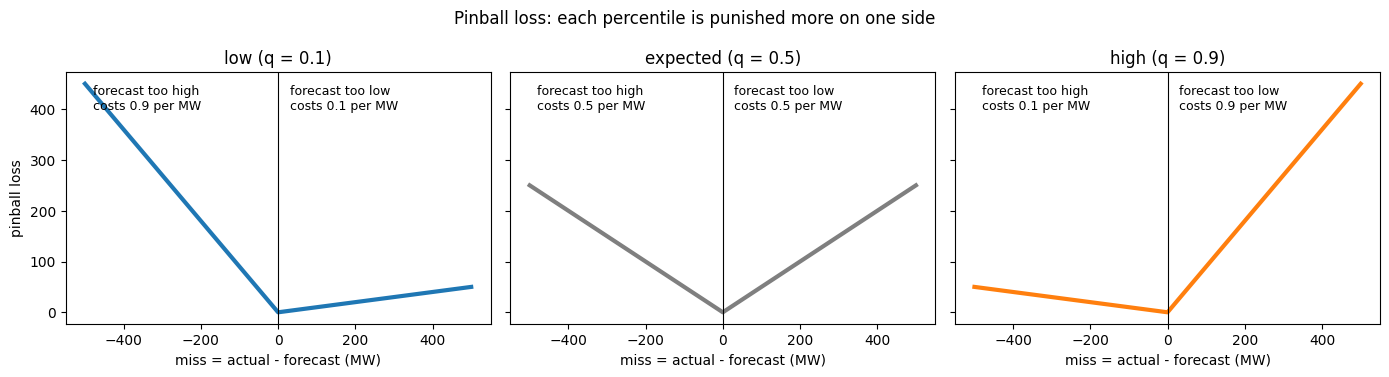

In [4]:
misses = np.linspace(-500, 500, 201)        # actual - forecast, in MW
names = ["low (q = 0.1)", "expected (q = 0.5)", "high (q = 0.9)"]
colors = ["tab:blue", "tab:gray", "tab:orange"]
quantiles = [0.1, 0.5, 0.9]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for i in range(3):
    loss = pinball(misses, 0, quantiles[i])
    axes[i].plot(misses, loss, color=colors[i], linewidth=3)
    axes[i].axvline(0, color="black", linewidth=0.8)
    axes[i].set_title(names[i])
    axes[i].set_xlabel("miss = actual - forecast (MW)")
    axes[i].text(-480, 400, "forecast too high\ncosts " + str(round(1 - quantiles[i], 1)) + " per MW", fontsize=9)
    axes[i].text(30, 400, "forecast too low\ncosts " + str(round(quantiles[i], 1)) + " per MW", fontsize=9)
axes[0].set_ylabel("pinball loss")
plt.suptitle("Pinball loss: each percentile is punished more on one side")
plt.tight_layout()
plt.show()

# Part 4 · The aha: the lowest pinball loss lands on the percentile
Take every hot summer afternoon (5 PM, **85 to 92 °F**). If you had to forecast **one number** for all of them, which
number gives the lowest **average** pinball loss? Try every number from 3,000 to 6,500 MW and see.

55 hot afternoons


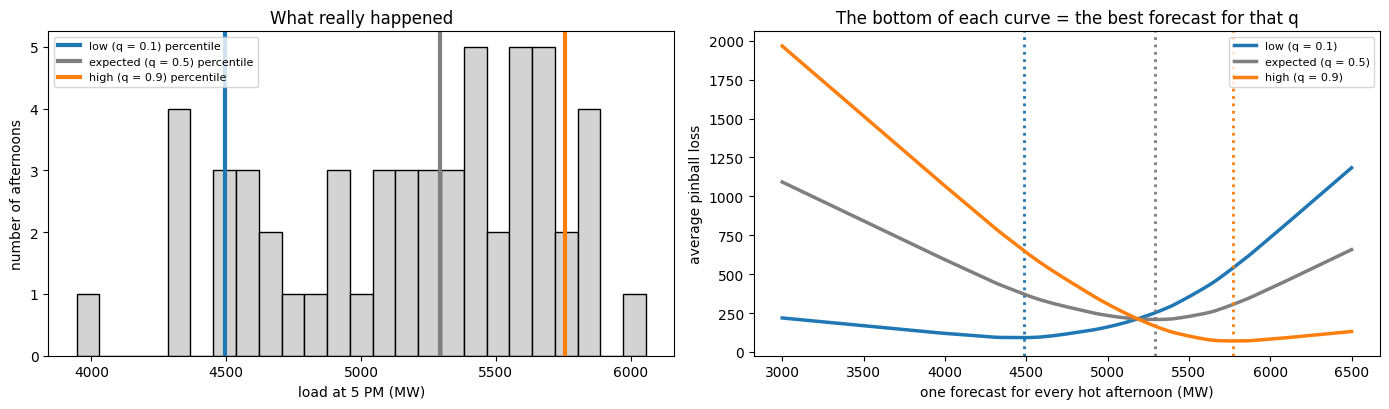

low (q = 0.1)        lowest pinball loss at 4485 MW | percentile of the data: 4495 MW
expected (q = 0.5)   lowest pinball loss at 5290 MW | percentile of the data: 5291 MW
high (q = 0.9)       lowest pinball loss at 5770 MW | percentile of the data: 5757 MW


In [5]:
hot = five_pm[(five_pm["temp_f"] >= 85) & (five_pm["temp_f"] <= 92)]
loads = hot["load_mw"].values
print(len(loads), "hot afternoons")

candidates = np.arange(3000, 6501, 5)        # every forecast we try, in MW
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# Left: what really happened on those afternoons, with the 10th, 50th and 90th percentile
axes[0].hist(loads, bins=25, color="lightgray", edgecolor="black")
for i in range(3):
    axes[0].axvline(np.percentile(loads, 100 * quantiles[i]), color=colors[i], linewidth=3, label=names[i] + " percentile")
axes[0].set_xlabel("load at 5 PM (MW)")
axes[0].set_ylabel("number of afternoons")
axes[0].set_title("What really happened")
axes[0].legend(fontsize=8)

# Right: the average pinball loss of every candidate forecast, for each q
best = []
for i in range(3):
    average_loss = []
    for c in candidates:
        average_loss.append(np.mean(pinball(loads, c, quantiles[i])))
    winner = candidates[int(np.argmin(average_loss))]
    best.append(winner)
    axes[1].plot(candidates, average_loss, color=colors[i], linewidth=2.5, label=names[i])
    axes[1].axvline(winner, color=colors[i], linestyle=":", linewidth=2)
axes[1].set_xlabel("one forecast for every hot afternoon (MW)")
axes[1].set_ylabel("average pinball loss")
axes[1].set_title("The bottom of each curve = the best forecast for that q")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for i in range(3):
    print(names[i].ljust(20), "lowest pinball loss at", best[i], "MW | percentile of the data:", round(np.percentile(loads, 100 * quantiles[i])), "MW")

**The bottom of each curve sits on the percentile** (the dotted lines on the right land on the solid lines on the
left, within a few MW: with this few afternoons the bottom of each curve is a little flat). That's the whole trick:
**the forecast that minimizes the pinball loss for q IS the q-th percentile.** So a network trained to minimize it
for q = 0.9 learns to put about 9 hours in 10 below its high. (Koenker and Bassett, 1978, "Regression Quantiles".)

# Part 5 · A tiny network: three lines through a scatterplot
One number for every afternoon ignores the weather. Let the forecast depend on temperature: a Keras network with **one
Dense layer and 3 outputs** (low, expected, high), trained on the **pinball loss** for q = 0.1, 0.5 and 0.9. That's
FP2's recipe in miniature: FP2 just reads 192 hours with an LSTM first.

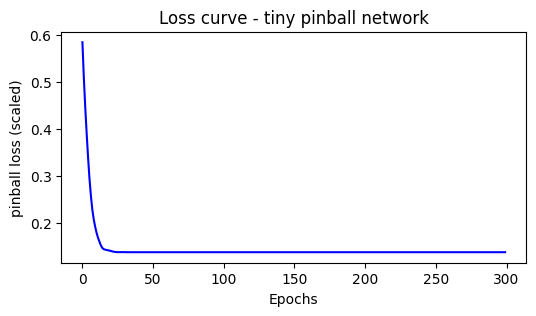

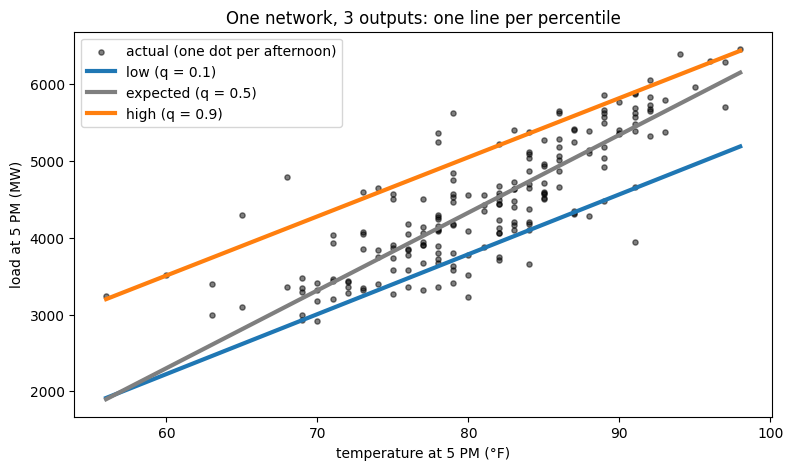

low (q = 0.1)        share of afternoons below this line: 10%
expected (q = 0.5)   share of afternoons below this line: 47%
high (q = 0.9)       share of afternoons below this line: 90%


In [6]:
# inputs and answers, scaled so the network trains quickly
temp_mean = five_pm["temp_f"].mean()
temp_std = five_pm["temp_f"].std()
load_mean = five_pm["load_mw"].mean()
load_std = five_pm["load_mw"].std()
X = ((five_pm["temp_f"] - temp_mean) / temp_std).values.reshape(-1, 1)
y = ((five_pm["load_mw"] - load_mean) / load_std).values

Q = np.array(quantiles, dtype="float32")


def pinball_loss(y_true, y_pred):
    """The pinball loss, averaged over the 3 percentiles (the same function as FP2 Part 5)."""
    error = keras.ops.expand_dims(y_true, -1) - y_pred
    return keras.ops.mean(keras.ops.maximum(Q * error, (Q - 1) * error))


tiny = keras.Sequential()
tiny.add(keras.Input(shape=(1,)))         # one input: the temperature
tiny.add(keras.layers.Dense(3))           # three outputs: the low, the expected and the high
tiny.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05), loss=pinball_loss)
history = tiny.fit(X, y, epochs=300, batch_size=64, verbose=0)

# loss curve - always look at this after a fit!
plt.figure(figsize=(6, 3))
plt.plot(history.history["loss"], "b")
plt.title("Loss curve - tiny pinball network")
plt.xlabel("Epochs")
plt.ylabel("pinball loss (scaled)")
plt.show()

# the three lines, back in MW
grid = np.linspace(X.min(), X.max(), 50).reshape(-1, 1)
lines = tiny.predict(grid, verbose=0) * load_std + load_mean        # (50 temperatures, 3 numbers)
fitted = tiny.predict(X, verbose=0) * load_std + load_mean
grid_temps = grid.ravel() * temp_std + temp_mean

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(five_pm["temp_f"], five_pm["load_mw"], s=14, color="black", alpha=0.5, label="actual (one dot per afternoon)")
for i in range(3):
    ax.plot(grid_temps, lines[:, i], color=colors[i], linewidth=3, label=names[i])
ax.set_xlabel("temperature at 5 PM (°F)")
ax.set_ylabel("load at 5 PM (MW)")
ax.set_title("One network, 3 outputs: one line per percentile")
ax.legend()
plt.show()

for i in range(3):
    share_below = np.mean(five_pm["load_mw"].values <= fitted[:, i])
    print(names[i].ljust(20), "share of afternoons below this line:", str(round(100 * share_below)) + "%")

**Read it:** the three lines climb with temperature (air conditioning), and about 10%, 50% and 90% of the dots sit
below the low, expected and high lines. Between the low and the high: about **80%** of afternoons, an 80% range. The
network was never told what a percentile is; the lopsided loss put each line there.

# Part 6 · 24 hours, 3 numbers each
Your FP2 LSTM does the same thing for **every one of the next 24 hours at once**. Its last layer gives 24 × 3 = **72
numbers**, and `Reshape` folds them into a table: one row per hour ahead, one column each for the low, expected and
high. The pinball loss is averaged over all 72. Here's that shape with a toy model (random weights, just to see it):

In [7]:
toy = keras.Sequential()
toy.add(keras.Input(shape=(192, 14)))                    # FP2's window: 168 past hours + 24 next hours, 14 columns
toy.add(keras.layers.LSTM(8))                            # reads the 192 rows
toy.add(keras.layers.Dense(24 * 3))                      # 72 numbers
toy.add(keras.layers.Reshape((24, 3)))                   # 24 hours x (low, expected, high)
one_window = np.zeros((1, 192, 14), dtype="float32")     # one made-up window, just to see the shape
out = toy.predict(one_window, verbose=0)
print("input:", one_window.shape, "-> output:", out.shape, "= 1 forecast x 24 hours x 3 numbers")
pd.DataFrame(out[0], columns=["low", "expected", "high"], index=range(1, 25)).head()

input:

 (1, 192, 14) -> output: (1, 24, 3) = 1 forecast x 24 hours x 3 numbers


,low,expected,high
1,0.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,0.0,0.0
4,0.0,0.0,0.0
5,0.0,0.0,0.0


# Part 7 · Back to the leaderboard
The leaderboard's CRPS for one hour is:

**CRPS = ( 0.5 × |actual − expected| + 0.1 × width + 1 × outside ) ÷ 1.5**

It's the same thing as **your three pinball losses added up**, divided by 1.5:

**CRPS = ( pinball(low, q = 0.1) + pinball(expected, q = 0.5) + pinball(high, q = 0.9) ) ÷ 1.5**

Check it on the four forecasters from FP2 Part 2 (all expected 3,000 MW, actual 3,100 MW):

In [8]:
def leaderboard_crps(actual, low, expected, high):
    """The leaderboard's formula (FP2 Part 2)."""
    width = high - low
    outside = max(low - actual, 0) + max(actual - high, 0)
    return (0.5 * abs(actual - expected) + 0.1 * width + 1 * outside) / 1.5


def crps_from_pinball(actual, low, expected, high):
    """The same score, built from three pinball losses."""
    total = pinball(actual, low, 0.1) + pinball(actual, expected, 0.5) + pinball(actual, high, 0.9)
    return float(total) / 1.5


forecasters = pd.DataFrame({"forecaster": ["no range (FP1)", "too narrow", "honest", "too wide"],
                            "low": [3000, 2980, 2850, 2000],
                            "expected": [3000, 3000, 3000, 3000],
                            "high": [3000, 3020, 3200, 4000]})
leaderboard_scores = []
pinball_scores = []
for i in range(len(forecasters)):
    row = forecasters.iloc[i]
    leaderboard_scores.append(round(leaderboard_crps(3100, row["low"], row["expected"], row["high"]), 1))
    pinball_scores.append(round(crps_from_pinball(3100, row["low"], row["expected"], row["high"]), 1))
forecasters["leaderboard CRPS (lower is better)"] = leaderboard_scores
forecasters["from 3 pinball losses"] = pinball_scores
forecasters

,forecaster,low,expected,high,leaderboard CRPS (lower is better),from 3 pinball losses
0,no range (FP1),3000,3000,3000,100.0,100.0
1,too narrow,2980,3000,3020,89.3,89.3
2,honest,2850,3000,3200,56.7,56.7
3,too wide,2000,3000,4000,166.7,166.7


**Same numbers.** Why it works for an hour where the actual lands **inside** the range:
- the low (q = 0.1) sits under the actual: 0.1 × (actual − low)
- the high (q = 0.9) sits over the actual: 0.1 × (high − actual)
- those two add up to **0.1 × width**, and the expected adds **0.5 × |actual − expected|**

When the actual lands **outside**, say above the high, the high's steep side kicks in (0.9 per MW instead of 0.1), and
that extra is the **1 × outside** term. So when your LSTM lowers its pinball loss in training, it's lowering the score
the leaderboard gives it. (This sum of pinball losses is the weighted interval score of Bracher et al., 2021.)

### The one-sentence version for your report
*Each of my three numbers is scored with a lopsided penalty (the pinball loss) that is smallest when it sits at its
percentile, so a low CRPS means my low, expected and high behave like a real 10th, 50th and 90th percentile.*

### Think about it (optional)
1. In Part 1, if you made q = 0.95 for the high, how much more would a too-low forecast cost than a too-high one? Would
   your range get wider or narrower?
2. In Part 4, change the temperature window to 70 to 78 °F. Do the three percentiles move closer together or farther
   apart? Why might that be?
3. In Part 5, the tiny network was trained on 2023-2025. Would you expect about 80% of 2026's afternoons inside its
   range? What does FP2 Part 6 do about that?

---
**Sources:** Koenker and Bassett (1978), Regression Quantiles, *Econometrica*. Bracher, Ray, Gneiting and Reich (2021),
Evaluating epidemic forecasts in an interval format, *PLOS Computational Biology*. Data: Iowa State Mesonet (Bradley
weather) and ISO New England (load).